# Демонстрация четырёх моделей атрибуции

Готовые CSV находятся в `data/mock/`. Выполните этот ноутбук целиком: повторная генерация не нужна. Для изменения допущений сначала выполните `01_generate_demo.ipynb`. Результаты сохраняются в `outputs/demo/attribution/`.


In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'data/raw/base.csv').exists())
sys.path.insert(0, str(ROOT/'src'))
from core.attribution import compute
MODELS = ['first', 'last', 'linear', 'position']
# Используем существующую выгрузку; повторная генерация не требуется.
DATA_DIR = ROOT/'data/mock'
input_manifest = json.loads((DATA_DIR/'manifest.json').read_text())
PARAMETERS = input_manifest['parameters']
BASE_SEED = PARAMETERS['SEED']
WINDOW_DAYS = PARAMETERS['ATTRIBUTION_WINDOW_DAYS']
POST_ATTENTION_HALF_LIFE_DAYS = PARAMETERS['POST_ATTENTION_HALF_LIFE_DAYS']  # только информация о сохранённых данных
TOP_K = 3
HORIZONS_DAYS = [7, 14]  # при необходимости добавьте 3
REPORT_HORIZON_DAYS = 7  # окно итоговой таблицы и выбора лидеров
assert REPORT_HORIZON_DAYS in HORIZONS_DAYS
assert HORIZONS_DAYS == sorted(set(HORIZONS_DAYS)) and min(HORIZONS_DAYS) > 0
OUTPUT = ROOT/'outputs/demo/attribution'
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False,'svg.fonttype':'none'})
def save(fig, name):
    fig.savefig(OUTPUT/(name+'.png'), dpi=145, bbox_inches='tight')
    fig.savefig(OUTPUT/(name+'.svg'), bbox_inches='tight')
    display(Image(filename=str(OUTPUT/(name+'.png'))))
    plt.close(fig)


## 1. Ручные ответы и граничные случаи

Каждый пример выполняется для четырёх моделей. Ожидаемая выручка задана явно, независимо от формул проверяемой функции. Для денежных сумм сравнение допускает только численную погрешность float (0,000001 ₽), а не округление до рубля. Проверка двух курсов начинается с двух позиций разной стоимости и одного заказа.


In [2]:
T = pd.Timestamp('2026-09-01 12:00', tz='Europe/Moscow')
def order(oid='o', time=T, amount=100., user='u'):
    return dict(order_id=oid,user_id_hash=user,timestamp=time,amount=amount,variable_costs=0.)
def touch(i, days=1, placement=None, user='u', time=None):
    return dict(touch_id=i,user_id_hash=user,placement_id=placement or f'p{i}',timestamp=time if time is not None else T-pd.Timedelta(days=days))
def same(expected):return {m:expected for m in MODELS}
cases = [
 ('Одно касание',[touch(1)],[order()],same({'o':{'p1':100}})),
 ('Два касания',[touch(1,2),touch(2,1)],[order()],{'first':{'o':{'p1':100}},'last':{'o':{'p2':100}},'linear':{'o':{'p1':50,'p2':50}},'position':{'o':{'p1':50,'p2':50}}}),
 ('Три касания',[touch(1,3),touch(2,2),touch(3,1)],[order(amount=300)],{'first':{'o':{'p1':300}},'last':{'o':{'p3':300}},'linear':{'o':{'p1':100,'p2':100,'p3':100}},'position':{'o':{'p1':120,'p2':60,'p3':120}}}),
 ('Четыре касания',[touch(i,5-i) for i in range(1,5)],[order()],{'first':{'o':{'p1':100}},'last':{'o':{'p4':100}},'linear':{'o':{f'p{i}':25 for i in range(1,5)}},'position':{'o':{'p1':40,'p2':10,'p3':10,'p4':40}}}),
 ('Нет касаний',[],[order()],same({'o':{'NO_TOUCH':100}})),
 ('Старше окна',[touch(1,time=T-pd.Timedelta(days=30,seconds=1))],[order()],same({'o':{'NO_TOUCH':100}})),
 ('Ровно 30 дней',[touch(1,30)],[order()],same({'o':{'p1':100}})),
 ('После оплаты',[touch(1,time=T+pd.Timedelta(seconds=1))],[order()],same({'o':{'NO_TOUCH':100}})),
 ('Ровно в оплату',[touch(1,time=T)],[order()],same({'o':{'p1':100}})),
 ('Чужой неоплаченный путь',[touch(1),touch(2,user='nonbuyer')],[order()],same({'o':{'p1':100}})),
 ('Без рекламной метки',[dict(touch(1),placement_id=None)],[order()],same({'o':{'NO_TOUCH':100}})),
 ('Повторная оплата, сброс',[touch(1,3),touch(2,2),touch(3,1)],[order('old',T-pd.Timedelta(days=2),200),order()],{'first':{'old':{'p1':200},'o':{'p3':100}},'last':{'old':{'p2':200},'o':{'p3':100}},'linear':{'old':{'p1':100,'p2':100},'o':{'p3':100}},'position':{'old':{'p1':100,'p2':100},'o':{'p3':100}}}),
 ('Повтор без новых касаний',[touch(1,3)],[order('old',T-pd.Timedelta(days=2),200),order()],same({'old':{'p1':200},'o':{'NO_TOUCH':100}})),
 ('Одно время, порядок ID',[touch(2,1),touch(1,1)],[order()],{'first':{'o':{'p1':100}},'last':{'o':{'p2':100}},'linear':{'o':{'p1':50,'p2':50}},'position':{'o':{'p1':50,'p2':50}}}),
 ('Повторные касания поста',[touch(1,3,placement='p1'),touch(2,2,placement='p1'),touch(3,1)],[order(amount=300)],{'first':{'o':{'p1':300}},'last':{'o':{'p3':300}},'linear':{'o':{'p1':200,'p3':100}},'position':{'o':{'p1':180,'p3':120}}}),
 ('Два курса, один заказ',[touch(1)],[order(amount=sum([70.,30.]))],same({'o':{'p1':100}})),
]
checks=[]
for name, ts, os, expected in cases:
    tt=pd.DataFrame(ts,columns=['touch_id','user_id_hash','placement_id','timestamp'])
    tt['timestamp']=pd.to_datetime(tt.timestamp,utc=True).dt.tz_convert('Europe/Moscow')
    oo=pd.DataFrame(os)
    for model in MODELS:
        a=compute(tt,oo,model,30)  # ручные примеры заданы для окна 30 дней
        actual=a.assign(placement_id=a.placement_id.fillna('NO_TOUCH')).groupby(['order_id','placement_id']).attributed_revenue.sum().to_dict()
        target={(oid,p):v for oid,ps in expected[model].items() for p,v in ps.items()}
        assert actual.keys()==target.keys(), (name,model,actual,target)
        for key in target:assert np.isclose(actual[key],target[key],rtol=0,atol=1e-6),(name,model,key)
        assert np.allclose(a.groupby('order_id').weight.sum(),1,rtol=0,atol=1e-10)
        checks.append(dict(case=name,model=model,result='PASS'))
checks=pd.DataFrame(checks)
display(checks.pivot(index='case',columns='model',values='result'))
checks.to_csv(OUTPUT/'manual_checks.csv',index=False)
print(f'{len(checks)} проверок пройдено. Разные заказы с одинаковым временем не входят: правило не определено.')


64 проверок пройдено. Разные заказы с одинаковым временем не входят: правило не определено.


model,first,last,linear,position
case,,,,
Без рекламной метки,PASS,PASS,PASS,PASS
Два касания,PASS,PASS,PASS,PASS
"Два курса, один заказ",PASS,PASS,PASS,PASS
Нет касаний,PASS,PASS,PASS,PASS
"Одно время, порядок ID",PASS,PASS,PASS,PASS
Одно касание,PASS,PASS,PASS,PASS
Повтор без новых касаний,PASS,PASS,PASS,PASS
"Повторная оплата, сброс",PASS,PASS,PASS,PASS
Повторные касания поста,PASS,PASS,PASS,PASS


## 2. Проверка сохранённой выборки

Читаем orders.csv, touches.csv, placements.csv и manifest.json из DATA_DIR. Параметры и границы наблюдения берутся из manifest.json; код генератора в основном запуске не выполняется. Входные файлы не перезаписываются. Результаты сохраняются в `outputs/demo/attribution/`.

Для каждого заказа проверяем сохранение выручки, сумму весов и допустимость касаний. Рейтинги по возрастным окнам считаются после полной атрибуции без перераспределения долей. Все модели работают с одними сохранёнными данными.


In [3]:
def load_saved_data(directory, manifest):
    orders = pd.read_csv(directory/'orders.csv')
    touches = pd.read_csv(directory/'touches.csv')
    posts = pd.read_csv(directory/'placements.csv')
    timezone = manifest['parameters']['TIMEZONE']
    for frame, columns in [(orders,['timestamp','previous_order_time']), (touches,['timestamp']), (posts,['publication_time'])]:
        for column in columns:
            frame[column] = pd.to_datetime(frame[column],utc=True,format='mixed').dt.tz_convert(timezone)
    assert orders.order_id.notna().all() and orders.order_id.is_unique
    assert touches.touch_id.notna().all() and touches.touch_id.is_unique
    assert posts.placement_id.notna().all() and posts.placement_id.is_unique
    assert touches.placement_id.isin(posts.placement_id).all()
    assert orders[['user_id_hash','timestamp','amount','amount_cents']].notna().all().all()
    assert touches[['user_id_hash','timestamp']].notna().all().all()
    assert posts.publication_time.notna().all()
    assert len(orders) == manifest['historical_order_count']
    assert int(orders.amount_cents.sum()) == manifest['historical_revenue_cents']
    assert np.allclose(orders.amount*100,orders.amount_cents,rtol=0,atol=1e-6)
    ordered=orders.sort_values(['user_id_hash','timestamp'])
    expected_previous=ordered.groupby('user_id_hash').timestamp.shift()
    assert (ordered.previous_order_time.eq(expected_previous) | (ordered.previous_order_time.isna() & expected_previous.isna())).all()
    start=pd.Timestamp(manifest['observation_start']).tz_convert(timezone)
    end=pd.Timestamp(manifest['observation_end_exclusive']).tz_convert(timezone)
    for frame in [orders,touches]:assert (frame.timestamp.ge(start)&frame.timestamp.lt(end)).all()
    assert touches.timestamp.ge(touches.placement_id.map(posts.set_index('placement_id').publication_time)).all()
    return dict(orders=orders,touches=touches,posts=posts,observation_start=start,observation_end=end)

base=load_saved_data(DATA_DIR,input_manifest)
input_hashes={name:hashlib.sha256((DATA_DIR/name).read_bytes()).hexdigest() for name in ['orders.csv','touches.csv','placements.csv','manifest.json']}
print('Загружены сохранённые данные:',len(base['orders']),'заказов,',len(base['touches']),'касаний.')
print('Параметры генерации из manifest.json:', 'seed =',BASE_SEED,'полураспад =',POST_ATTENTION_HALF_LIFE_DAYS)
placements=base['posts'].set_index('placement_id')
ids=placements.index.sort_values()
def calculate(ns):
    oo=ns['orders'].assign(variable_costs=np.nan)
    tt=ns['touches'][['touch_id','user_id_hash','placement_id','timestamp']]
    assert oo.order_id.is_unique and tt.touch_id.is_unique
    assert not oo.duplicated(['user_id_hash','timestamp']).any()
    assert oo.amount_cents.sum()==base['orders'].amount_cents.sum()
    assert tt.placement_id.isin(ids).all()
    order_map=oo.set_index('order_id');touch_map=tt.set_index('touch_id')
    results={}
    for model in MODELS:
        a=compute(tt,oo,model,WINDOW_DAYS)
        assert np.allclose(a.groupby('order_id').weight.sum().reindex(order_map.index),1,rtol=0,atol=1e-10)
        assert np.allclose(a.groupby('order_id').attributed_revenue.sum().reindex(order_map.index),order_map.amount,rtol=0,atol=1e-6)
        used=a[a.touch_id.notna()]
        ot=used.order_id.map(order_map.timestamp); t=used.touch_id.map(touch_map.timestamp)
        prev=used.order_id.map(order_map.previous_order_time)
        assert ((t<=ot)&(t>=ot-pd.Timedelta(days=WINDOW_DAYS))&(prev.isna()|t.gt(prev))).all()
        assert used.order_id.map(order_map.user_id_hash).equals(used.touch_id.map(touch_map.user_id_hash))
        results[model]=a
    return results
baseline=calculate(base)
for model,a in baseline.items():
    buyers=base['touches'][base['touches'].user_group.eq('buyer')]
    alt=compute(buyers,base['orders'].assign(variable_costs=np.nan,lead_id=None),model,WINDOW_DAYS)
    pd.testing.assert_frame_equal(a.reset_index(drop=True),alt.reset_index(drop=True))
def revenues(result):
    return pd.DataFrame({m:a.groupby('placement_id').attributed_revenue.sum().reindex(ids,fill_value=0) for m,a in result.items()})
base_revenue=revenues(baseline)
base_revenue.to_csv(OUTPUT/'baseline_revenue.csv')

no_touch=pd.Series({m:a.loc[a.touch_id.isna(),'attributed_revenue'].sum() for m,a in baseline.items()},name='Без сгенерированных касаний, ₽')

# Срез по времени заказа после полной атрибуции, без перераспределения долей.
def horizon_revenues(ns, result, horizon):
    published = placements.publication_time
    ends = published + pd.Timedelta(days=horizon)
    complete = published.ge(ns['observation_start']) & ends.le(ns['observation_end'])
    order_time = ns['orders'].set_index('order_id').timestamp
    columns = {}
    for model, a in result.items():
        start = a.placement_id.map(published)
        end = a.placement_id.map(ends)
        time = a.order_id.map(order_time)
        keep = time.ge(start) & time.lt(end)
        value = a.loc[keep].groupby('placement_id').attributed_revenue.sum().reindex(ids, fill_value=0.)
        value.loc[~complete.reindex(ids)] = np.nan
        columns[model] = value
    return pd.DataFrame(columns)

# Все окна сравниваются на общей когорте полного максимального горизонта.
common_ids = ids[(placements.publication_time.reindex(ids).ge(base['observation_start']) &
                 (placements.publication_time.reindex(ids)+pd.Timedelta(days=max(HORIZONS_DAYS))).le(base['observation_end'])).to_numpy()]
assert len(common_ids) >= TOP_K
coverage=[]
for h in HORIZONS_DAYS:
    v=horizon_revenues(base,baseline,h)
    coverage.append(dict(horizon_days=h,total_posts=len(ids),complete_posts=int(v[MODELS[0]].notna().sum()),common_posts=len(common_ids)))
pd.DataFrame(coverage).to_csv(OUTPUT/'horizon_coverage.csv',index=False)

# Проверка границ и отсутствия перенормировки на независимом примере.
probe_id=common_ids[0]; t0=placements.loc[probe_id,'publication_time']
probe_orders=pd.DataFrame({'order_id':[1,2,3,4], 'timestamp':[t0,t0+pd.Timedelta(days=3)-pd.Timedelta(seconds=1),t0+pd.Timedelta(days=3),t0-pd.Timedelta(seconds=1)]})
probe_a=pd.DataFrame({'order_id':[1,2,3,4], 'placement_id':[probe_id]*4,'attributed_revenue':[25.,50.,100.,200.]})
probe_ns=dict(base,orders=probe_orders)
assert horizon_revenues(probe_ns,{m:probe_a for m in MODELS},3).loc[probe_id].eq(75.).all()
probe_ns=dict(probe_ns,observation_end=t0+pd.Timedelta(days=3)-pd.Timedelta(seconds=1))
assert horizon_revenues(probe_ns,{m:probe_a for m in MODELS},3).loc[probe_id].isna().all()

def horizon_rows(ns,result,config,seed):
    rows=[]
    previous=None
    for h in HORIZONS_DAYS:
        values=horizon_revenues(ns,result,h).loc[common_ids]
        assert values.notna().all().all()
        if previous is not None: assert (values.to_numpy()+1e-7 >= previous.to_numpy()).all()
        previous=values
        for model in MODELS:
            ranks=values[model].rank(ascending=False,method='first')
            for pid in common_ids:
                rows.append(dict(config=config,seed=seed,horizon_days=h,model=model,placement_id=pid,revenue=values.loc[pid,model],rank=ranks[pid],top3=bool(ranks[pid]<=TOP_K)))
    return rows
baseline_horizons=pd.DataFrame(horizon_rows(base,baseline,'Сохранённая выборка',BASE_SEED))
baseline_horizons.to_csv(OUTPUT/'horizon_baseline.csv',index=False)


Загружены сохранённые данные: 628 заказов, 4323 касаний.
Параметры генерации из manifest.json: seed = 42 полураспад = 7.0


## Дополнительная диагностика: D7/D14

Сравнение одинакового возраста постов и календарь лидеров сохранены для диагностики. Они не служат ответом на событийную гипотезу.


Приписанная выручка за первые 7 дней, ₽. Полная таблица: 30 постов.
Покрытие окон:
Общая выручка: 5904671.67 ₽
Без подходящих касаний: 1862158.33 ₽


,Пост,Публикация (МСК),Категория,first,last,linear,position
0,1829,04.08.2026 18:50,regular,406573.34,339713.34,365925.01,368812.34
1,1830,05.08.2026 19:03,regular,221720.00,184795.00,203280.00,203271.00
2,1831,06.08.2026 19:23,regular,141220.00,112275.00,121461.67,123576.00
3,1833,07.08.2026 17:22,regular,71110.00,146710.00,114798.33,112443.00
4,1834,08.08.2026 09:05,discount,61225.00,118635.00,92924.17,91726.50
5,1866,25.08.2026 16:51,regular,32840.00,55745.00,42800.83,43397.50
6,1854,17.08.2026 19:05,regular,23695.00,58640.00,41167.50,41167.50
7,1857,20.08.2026 19:11,regular,31850.00,34800.00,30508.33,31635.00
8,1859,22.08.2026 13:19,course_launch,14950.00,43325.00,29137.50,29137.50
9,1860,23.08.2026 11:51,regular,19950.00,30375.00,25162.50,25162.50


,horizon_days,total_posts,complete_posts,common_posts
0,7,48,37,30
1,14,48,30,30


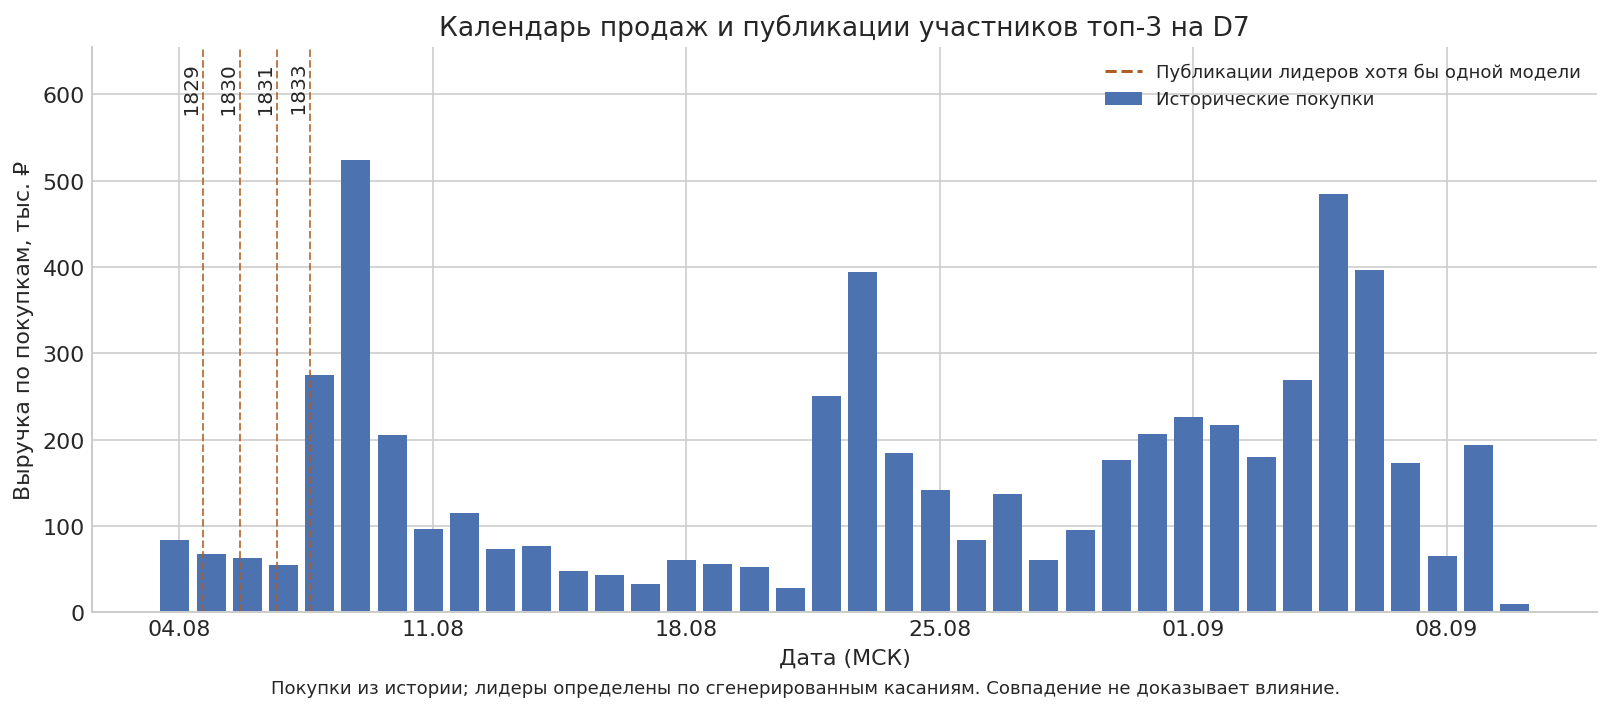

In [4]:
# Одна таблица: реальные категории и даты, модельная выручка за выбранный возраст.
values=horizon_revenues(base,baseline,REPORT_HORIZON_DAYS).loc[common_ids]
report=placements.loc[common_ids,['post_id','publication_time','post_type']].copy()
for model in MODELS:report[model]=values[model]
# Для вывода — по средней приписанной выручке четырёх моделей; это только порядок строк.
report=report.loc[values.mean(axis=1).sort_values(ascending=False,kind='stable').index]
report.to_csv(OUTPUT/'placement_comparison.csv',index_label='placement_id')
shown=report.copy()
shown['publication_time']=shown.publication_time.dt.strftime('%d.%m.%Y %H:%M')
shown=shown.rename(columns={'post_id':'Пост','publication_time':'Публикация (МСК)','post_type':'Категория'})
shown[MODELS]=shown[MODELS].round(2)
print(f'Приписанная выручка за первые {REPORT_HORIZON_DAYS} дней, ₽. Полная таблица: {len(shown)} постов.')
with pd.option_context('display.max_rows',None,'display.max_columns',None):display(shown.reset_index(drop=True))
print('Покрытие окон:')
display(pd.DataFrame(coverage))

# Лидеры — объединение топ-3 каждой модели в выбранном окне, с теми же правилами равенства.
ranked=baseline_horizons[baseline_horizons.horizon_days.eq(REPORT_HORIZON_DAYS)]
leader_ids=ranked.loc[ranked['rank'].le(TOP_K),'placement_id'].unique()
leader_posts=placements.loc[leader_ids].sort_values('publication_time')
daily=base['orders'].groupby(base['orders'].timestamp.dt.normalize()).amount.sum()
days=pd.date_range(base['observation_start'],base['observation_end']-pd.Timedelta(days=1),freq='D')
daily=daily.reindex(days,fill_value=0.)
assert np.isclose(daily.sum(),base['orders'].amount.sum(),rtol=0,atol=1e-6)
daily.rename('recorded_revenue').rename_axis('date').to_csv(OUTPUT/'calendar_sales.csv')
leader_posts[['post_id','publication_time','post_type']].to_csv(OUTPUT/'calendar_leaders.csv')
import matplotlib.dates as mdates
fig,ax=plt.subplots(figsize=(11,4.8),layout='constrained')
ax.bar(daily.index,daily.to_numpy()/1000,width=.8,color='#4C72B0',label='Исторические покупки')
for row in leader_posts.itertuples():
    ax.axvline(row.publication_time,color='#B15C21',linestyle='--',linewidth=1,alpha=.8)
    ax.text(row.publication_time,.97,f' {int(row.post_id)}',rotation=90,ha='right',va='top',transform=ax.get_xaxis_transform(),fontsize=10)
ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m',tz=base['observation_start'].tz))
ax.set(ylabel='Выручка по покупкам, тыс. ₽',xlabel='Дата (МСК)',ylim=(0,daily.max()/1000*1.25),
       title=f'Календарь продаж и публикации участников топ-3 на D{REPORT_HORIZON_DAYS}')
ax.plot([],[],color='#B15C21',linestyle='--',label='Публикации лидеров хотя бы одной модели')
ax.legend(loc='upper right',fontsize=9)
fig.supxlabel('Покупки из истории; лидеры определены по сгенерированным касаниям. Совпадение не доказывает влияние.',fontsize=9)
save(fig,'calendar_sales_and_leaders')
manifest={'experiment_only':True,'input_mode':'saved_csv','input_directory':str(DATA_DIR.relative_to(ROOT)),
          'input_sha256':input_hashes,'generation_parameters':PARAMETERS,
          'window_days':WINDOW_DAYS,'horizons_days':HORIZONS_DAYS,'report_horizon_days':REPORT_HORIZON_DAYS,
          'common_placement_ids':common_ids.tolist(),'manual_checks_passed':len(checks),
          'engine_sha256':hashlib.sha256((ROOT/'src/core/attribution.py').read_bytes()).hexdigest(),
          'as_of':pd.Timestamp.now(tz='UTC').isoformat()}
(OUTPUT/'manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2))
print('Общая выручка:',round(base['orders'].amount.sum(),2),'₽')
print('Без подходящих касаний:',round(no_touch.iloc[0],2),'₽')


## Как читать результат

Таблица сравнивает четыре правила распределения выручки. Категории публикаций — исходная разметка, которая может содержать ошибки. Они не меняют расчёт. Равенство результатов моделей не доказывает эффективность поста.

D7/D14 отсчитываются от публикации по времени покупки: [публикация, публикация + H). Веса рассчитываются до среза и не перенормируются. Во всех окнах сравнивается один набор постов с полностью наблюдаемым максимальным горизонтом; при его изменении состав может поменяться. Отсутствие событий в полном окне означает нулевую выручку.

Календарь помогает заметить совпадение публикаций с всплесками покупок. Он не отделяет влияние поста от внешнего спроса. Частота попадания в топ-3 не рассчитывается: здесь одна сохранённая выборка. Изменение угасания требует нового запуска генератора.
